## Spatial Model Error Mapping
- V2 is for season length and other statistics calculated from OutputStatsV2.py

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

In [7]:
# Load the CSV data for all six model runs
model_files = {
    's00000000_ghec_v0003': '../outputV2_snotel_sites_v2_s00000000_ghec_v0003.csv',
    's01011010_ghec_v0004': '../outputV2_snotel_sites_v2_s01011010_ghec_v0004.csv',
    's01011010_ghelaps_v0008': '../outputV2_snotel_sites_v2_s01011010_ghelaps_v0008.csv',
    's01011010_gbc_v0005': '../outputV2_snotel_sites_v2_s01011010_gbc_v0005.csv',
    's01011010_ghelaps_veg_v0009': '../outputV2_snotel_sites_v2_s01011010_ghelaps_veg_v0009.csv',
    's01012010_ghelaps_v0011': '../outputV2_snotel_sites_v2_s01012010_ghelaps_v0011.csv',
}
dfs = {name: pd.read_csv(path) for name, path in model_files.items()}

# Single dataframe used by the peak analysis section below
df = dfs['s01011010_gbc_v0005']
df.head()

,site,latitude,longitude,avg_snow_days_snotel,avg_snow_days_model,avg_snow_days_model_all,avg_onset_wydoy_model_all,avg_meltout_wydoy_model_all,n_matched_snow_years,n_snow_years_model,avg_peak_wydoy_snotel,avg_peak_wydoy_model,avg_peak_wydoy_model_all,avg_peak_swe_snotel,avg_peak_swe_model,avg_peak_swe_model_all,n_matched_peak_years,n_peak_years_model
0,Forestdale Creek,38.682311,-119.960653,204.9,201.4,201.6,40.3,243.8,14,15,180.6,178.6,179.1,877.0,887.200012,904.7,14,15
1,Horse Meadow,38.836411,-119.888317,183.2,173.9,179.5,38.2,230.4,9,11,170.3,179.8,182.0,435.0,444.600006,534.4,9,11
2,Burnside Lake,38.719328,-119.895194,190.8,190.5,190.5,41.1,237.8,15,15,177.0,180.9,180.9,674.1,759.700012,759.7,15,15
3,Summit Meadow,38.397400,-119.536217,179.2,187.7,199.9,34.6,237.9,6,9,183.2,186.8,187.1,387.7,402.200012,520.1,6,9
4,Carson Pass,38.692667,-120.002128,206.5,199.2,199.2,38.8,240.0,12,13,182.7,180.6,180.9,816.2,765.099976,781.7,12,13


In [ ]:
df[df.site == 'Pepper Creek']

In [8]:
# Remove sites where snotel has less than 5 years
dfs = {name: d[d['n_matched_snow_years'] >= 5] for name, d in dfs.items()}
df = df[df['n_matched_snow_years'] >= 5]

### Snow Days
Compare model snow days to snotel

In [9]:
snow_days = df[['site','latitude','longitude','avg_snow_days_snotel','avg_snow_days_model']]

In [10]:
snow_days['model_snotel_ddays'] = snow_days['avg_snow_days_model'] - snow_days['avg_snow_days_snotel']

/tmp/ipykernel_2412/2386264500.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  snow_days['model_snotel_ddays'] = snow_days['avg_snow_days_model'] - snow_days['avg_snow_days_snotel']


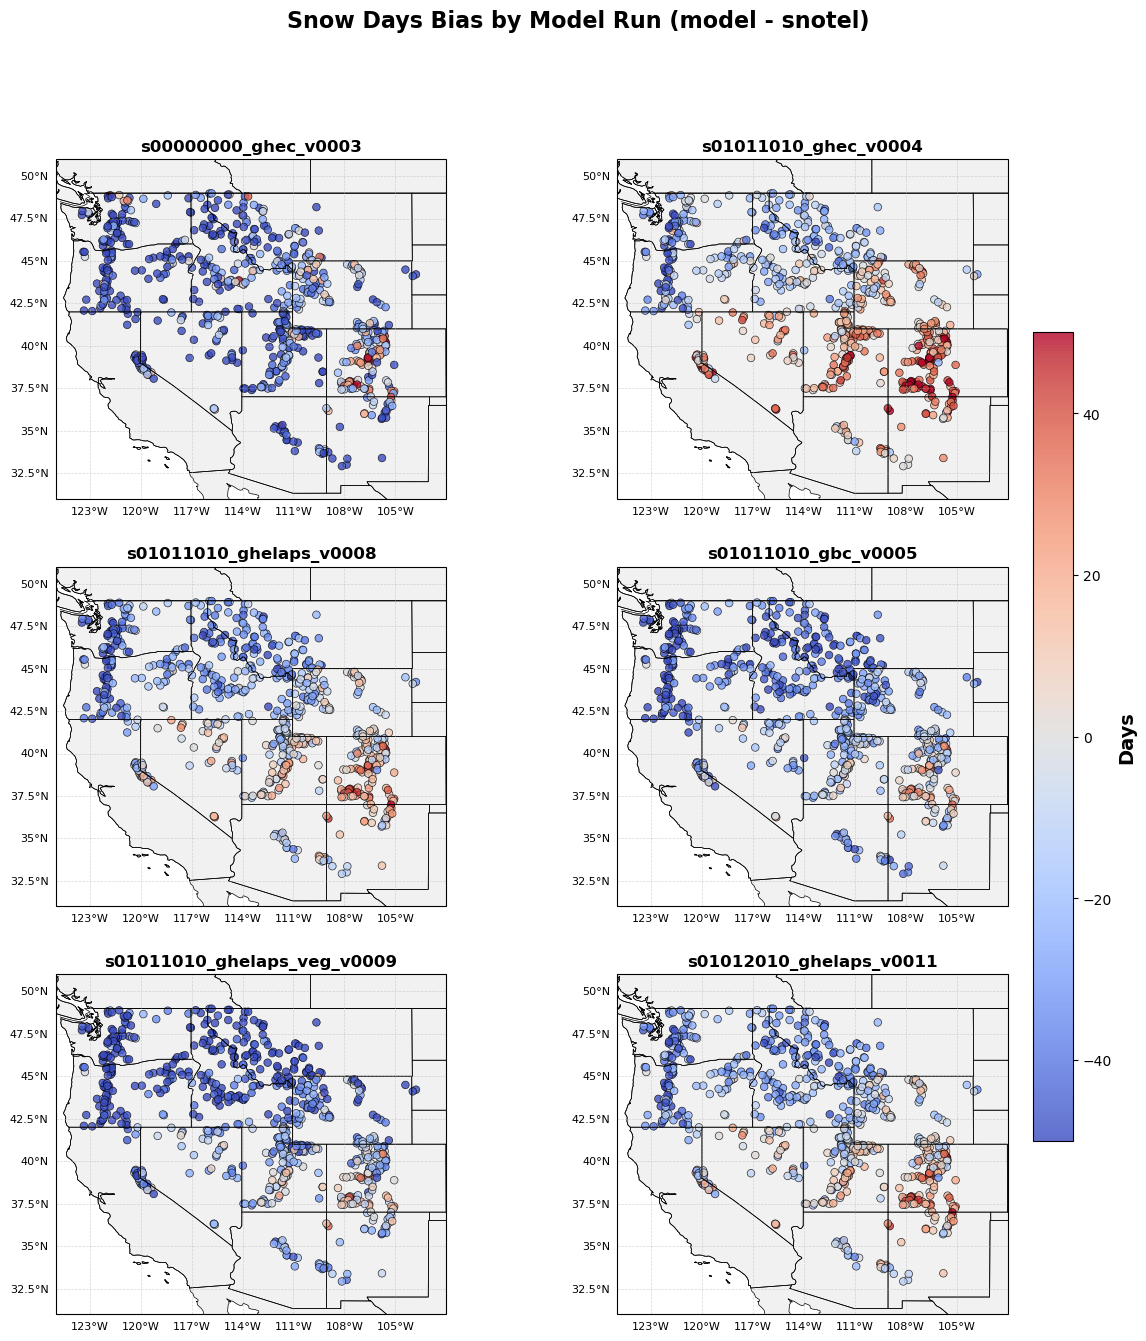

In [11]:
# Snow days map - one subplot per model run
fig, axes = plt.subplots(3, 2, figsize=(16, 15), subplot_kw={'projection': ccrs.PlateCarree()})

for ax, (name, model_df) in zip(axes.flat, dfs.items()):
    model_snow_days = model_df[['site', 'latitude', 'longitude', 'avg_snow_days_snotel', 'avg_snow_days_model']].copy()
    model_snow_days['model_snotel_ddays'] = model_snow_days['avg_snow_days_model'] - model_snow_days['avg_snow_days_snotel']

    ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    scatter = ax.scatter(model_snow_days['longitude'], model_snow_days['latitude'],
                         c=model_snow_days['model_snotel_ddays'],
                         s=30,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=-50,
                         vmax=50,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    ax.set_title(name, fontsize=12, fontweight='bold')
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

fig.suptitle('Snow Days Bias by Model Run (model - snotel)', fontsize=16, fontweight='bold')
cbar = fig.colorbar(scatter, ax=axes, orientation='vertical', pad=0.02, shrink=0.7)
cbar.set_label('Days', fontsize=14, fontweight='bold')
#fig.savefig('../images/ElevationMap.pdf', bbox_inches='tight')

#### Analysis
- Each panel looks essentially the same as a bias plot, but ghelaps does have some sites in AZ where bias is positive but snow days are negative.

### Peak SWE

Compare model peak SWE date to snotel, in day of water year (Oct 1 = day 1). `OutputStatsV2.py` computes `avg_peak_wydoy_*` this way (rather than calendar day-of-year) so that a peak occurring in Oct-Dec and one occurring in Jan-Jul are on the same continuous, averaging-safe scale — calendar DOY would otherwise wrap an early-season peak to a large value that isn't comparable to a late-season peak's small one.

In [12]:
peak_doy = df[['site','latitude','longitude','avg_peak_wydoy_snotel','avg_peak_wydoy_model']]

In [13]:
peak_doy['model_snotel_ddoy'] = peak_doy['avg_peak_wydoy_model'] - peak_doy['avg_peak_wydoy_snotel']

/tmp/ipykernel_2412/536697359.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  peak_doy['model_snotel_ddoy'] = peak_doy['avg_peak_wydoy_model'] - peak_doy['avg_peak_wydoy_snotel']


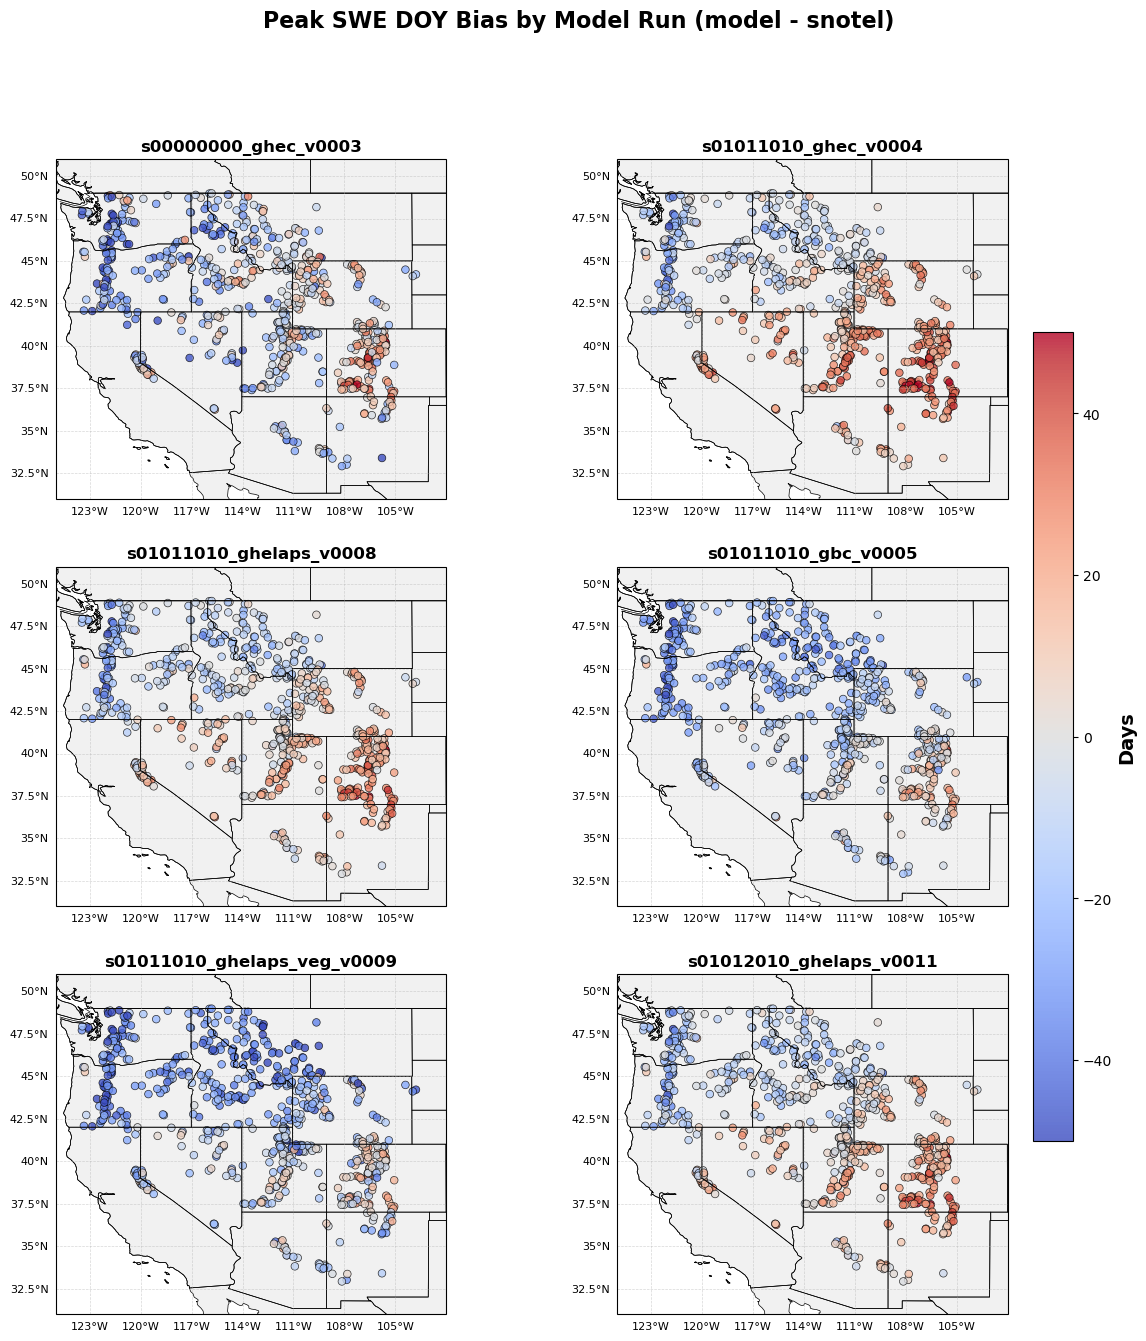

In [14]:
# Peak SWE DOY map - one subplot per model run
fig, axes = plt.subplots(3, 2, figsize=(16, 15), subplot_kw={'projection': ccrs.PlateCarree()})

for ax, (name, model_df) in zip(axes.flat, dfs.items()):
    model_peak_doy = model_df[['site', 'latitude', 'longitude', 'avg_peak_wydoy_snotel', 'avg_peak_wydoy_model']].copy()
    model_peak_doy['model_snotel_ddoy'] = model_peak_doy['avg_peak_wydoy_model'] - model_peak_doy['avg_peak_wydoy_snotel']

    ax.set_extent([-125, -102, 31, 51], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    scatter = ax.scatter(model_peak_doy['longitude'], model_peak_doy['latitude'],
                         c=model_peak_doy['model_snotel_ddoy'],
                         s=30,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=-50,
                         vmax=50,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    ax.set_title(name, fontsize=12, fontweight='bold')
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

fig.suptitle('Peak SWE DOY Bias by Model Run (model - snotel)', fontsize=16, fontweight='bold')
cbar = fig.colorbar(scatter, ax=axes, orientation='vertical', pad=0.02, shrink=0.7)
cbar.set_label('Days', fontsize=14, fontweight='bold')
#fig.savefig('../images/ElevationMap.pdf', bbox_inches='tight')

#### Unusual sites: shorter model season but later model peak
Identify sites where the model season is much shorter than observed (`model_snotel_ddays` very negative) while the model peak SWE date is much later than observed (`model_snotel_ddoy` very positive) — an unexpected combination.

In [15]:
# Combine the two diagnostics on site
unusual = snow_days[['site','latitude','longitude','model_snotel_ddays']].merge(
    peak_doy[['site','model_snotel_ddoy']], on='site'
)

# Score is only large when BOTH anomalies are present and severe:
# shorter model season (ddays << 0) and later model peak (ddoy >> 0).
# Using the min of the two "unusualness" directions means one large term
# can't inflate the score if the other condition isn't also met.
unusual['unusual_score'] = np.minimum(-unusual['model_snotel_ddays'], unusual['model_snotel_ddoy'])

top5 = unusual.sort_values('unusual_score', ascending=False).head(5)
top5[['site','latitude','longitude','model_snotel_ddays','model_snotel_ddoy','unusual_score']]

,site,latitude,longitude,model_snotel_ddays,model_snotel_ddoy,unusual_score
321,Bar M,34.861420,-111.604973,-19.7,22.6,19.7
1,Horse Meadow,38.836411,-119.888317,-9.3,9.5,9.3
50,Sargents Mesa,38.290000,-106.370000,-8.2,13.5,8.2
48,Long Draw Resv,40.511539,-105.765404,-13.7,7.8,7.8
31,Ute Creek,37.610000,-105.370000,-11.2,7.8,7.8
